# Prediksi Nilai Ujian Siswa Berdasarkan Aktivitas Belajar
### Implementasi Multiple Linear Regression & Konsep Polynomial Regression (OLS Normal Equation)
**Tugas Minggu 2 Bootcamp Data Science & AI UBIG • Jumat, 16 Oktober 2026**  
**Team 1 | Shift Malam — SMK PGRI 3 Malang**

---

### Identitas Tim & Fokus Kontribusi
| Nama Anggota | Peran & Fokus Kontribusi | Institusi / Kelas |
| :--- | :--- | :--- |
| **Abhiraffa Hamizan** | Perumusan Business Understanding, interpretasi koefisien regresi, analisis evaluasi model, dan penyusunan kesimpulan strategis. | SMK PGRI 3 Malang (Shift Malam) |
| **Panca Raditya** | Implementasi Data Preparation, Data Preprocessing, fungsi matriks OLS Normal Equation, dan eksperimen Polynomial Regression. | SMK PGRI 3 Malang (Shift Malam) |
| **Alexandra Azmi** | Eksplorasi distribusi data (EDA), analisis outlier (Boxplot, IQR, Z-Score), matriks korelasi, serta visualisasi grafik prediksi. | SMK PGRI 3 Malang (Shift Malam) |

---

### Goals & Pencapaian Tim Minggu Ini
1. **Menuntaskan Pipeline Data Science End-to-End**: Menyelesaikan tahapan terstruktur mulai dari *Business Understanding*, *Data Preparation*, *Exploratory Data Analysis (EDA)*, *Data Preprocessing*, *Modelling*, *Evaluation*, hingga *Conclusion* pada dataset `student_performance.csv` (240 baris, 5 kolom).
2. **Menguasai Perhitungan Matriks OLS Normal Equation**: Membangun algoritma Multiple Linear Regression secara mandiri berbasis aljabar linier murni $\beta = (X^T X)^{-1} X^T y$ untuk mengestimasi parameter bias ($\beta_0$) dan bobot kemiringan ($\beta_1, \dots, \beta_4$).
3. **Mengevaluasi Akurasi & Kestabilan Model**: Mengukur performa menggunakan lima metrik regresi ($R^2$, Adjusted $R^2$, MSE, RMSE, dan MAE) serta memverifikasi ketiadaan *overfitting* maupun *underfitting* antara data Train (80%) dan Test (20%).
4. **Memahami & Menguji Konsep Polynomial Regression**: Mengeksplorasi pembentukan matriks desain Vandermonde (`np.vander`) untuk memodelkan hubungan kurvilinear dan membandingkannya terhadap regresi linier.

## 1. BUSINESS UNDERSTANDING

### 1.1 Latar Belakang & Masalah (Pain Point)
* **Latar Belakang**: Sebuah lembaga bimbingan belajar ingin mengoptimalkan sistem pemantauan akademik guna membantu siswa mencapai hasil belajar yang maksimal. Lembaga menyimpan data historis aktivitas akademik yang mencakup mata pelajaran yang diikuti (`course_name`), nomor kelas (`class_number`), durasi jam belajar mandiri harian (`study_hours`), nilai ujian sebelumnya (`last_exam_score`), serta nilai ujian akhir (`exam_score`).
* **Masalah (Pain Point)**: Evaluasi performa siswa yang masih dilakukan secara manual dan reaktif setelah ujian akhir selesai membuat tim akademis terlambat mendeteksi siswa yang berisiko memperoleh nilai di bawah standar kelulusan (nilai < 70). Selain itu, lembaga belum memiliki ukuran kuantitatif mengenai seberapa besar kontribusi jam belajar mandiri dibandingkan nilai ujian sebelumnya terhadap capaian nilai akhir.

### 1.2 Solusi & Tujuan Proyek
* **Solusi**: Membangun model *machine learning* berbasis **Multiple Linear Regression** dan mengeksplorasi **Polynomial Regression** melalui tahapan data science terstruktur.
* **Tujuan**: Memperoleh persamaan regresi objektif yang akurat untuk memprediksi nilai ujian akhir siswa, sehingga lembaga dapat meluncurkan **Early Warning System** (sistem peringatan dini) guna memberikan intervensi belajar secara proaktif sebelum ujian berlangsung.

### 1.3 Deskripsi Kolom Dataset (`student_performance.csv`)
| Nama Kolom | Tipe Data Awal | Peran Variabel | Penjelasan & Karakteristik |
| :--- | :--- | :--- | :--- |
| `course_name` | object (String) | Fitur Independen ($x_1$) | Mata pelajaran yang diikuti siswa: *History*, *Math*, atau *Physics*. |
| `class_number` | float64 | Fitur Independen ($x_2$) | Nomor kelas/kelompok belajar siswa (Bernilai diskrit: 1.0, 2.0, 3.0, 4.0). |
| `study_hours` | float64 | Fitur Independen ($x_3$) | Durasi jam belajar mandiri harian siswa (Rentang: 0.5 s.d. 9.8 jam). |
| `last_exam_score` | float64 | Fitur Independen ($x_4$) | Nilai hasil ujian siswa pada periode sebelumnya (Rentang: 30.0 s.d. 99.0). |
| `exam_score` | int64 | Target Dependen ($y$) | Nilai ujian akhir siswa yang menjadi target prediksi (Rentang: 20 s.d. 100). |

## 2. DATA PREPARATION

Tahap Data Preparation bertujuan untuk mengimpor pustaka yang dibutuhkan, memuat dataset mentah ke dalam DataFrame Pandas, serta melakukan inspeksi awal terhadap struktur data, kelengkapan nilai, dan duplikasi baris.

### 2.1 Import Library
Pustaka dasar analisis data mencakup NumPy untuk komputasi matriks aljabar linier, Pandas untuk manipulasi tabel DataFrame, serta Matplotlib dan Seaborn untuk visualisasi grafis.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 10

### 2.2 Load Dataset
Membaca berkas `student_performance.csv` ke dalam variabel DataFrame `df` menggunakan fungsi `pd.read_csv()`.

In [2]:
df = pd.read_csv('student_performance.csv')
print("Dataset student_performance.csv berhasil dimuat.")

Dataset student_performance.csv berhasil dimuat.


### 2.3 Menampilkan Sampel Data Teratas & Terbawah
Memeriksa 5 baris pertama (`df.head()`) dan 5 baris terakhir (`df.tail()`) untuk melihat representasi format data.

In [3]:
df.head()

,course_name,class_number,study_hours,last_exam_score,exam_score
0,History,1.0,4.1,65.0,61
1,Math,2.0,9.5,65.0,95
2,Math,3.0,7.5,NaN,90
3,History,1.0,6.2,72.0,80
4,Physics,NaN,2.0,56.0,45


In [4]:
df.tail()

,course_name,class_number,study_hours,last_exam_score,exam_score
235,History,1.0,3.4,75.0,47
236,Physics,NaN,5.1,46.0,67
237,NaN,2.0,6.6,NaN,76
238,Physics,2.0,NaN,76.0,64
239,History,4.0,9.3,75.0,98


### 2.4 Menampilkan Dimensi dan Jumlah Elemen Data
Menggunakan atribut `.shape` untuk mengetahui jumlah baris dan kolom, serta atribut `.size` untuk total seluruh elemen sel data.

In [5]:
print("Dimensi Data (baris, kolom) :", df.shape)
print("Total Elemen Data (size)      :", df.size)

Dimensi Data (baris, kolom) : (240, 5)
Total Elemen Data (size)      : 1200


### 2.5 Menampilkan Informasi Struktur dan Tipe Data
Metode `.info()` menampilkan ringkasan jumlah baris non-null, pemakaian memori, dan tipe data setiap kolom.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   course_name      201 non-null    str    
 1   class_number     192 non-null    float64
 2   study_hours      204 non-null    float64
 3   last_exam_score  204 non-null    float64
 4   exam_score       240 non-null    int64  
dtypes: float64(3), int64(1), str(1)
memory usage: 9.5 KB


### 2.6 Menampilkan Nama Kolom dan Jumlah Nilai Unik
Mengecek nama kolom menggunakan `df.columns` dan menghitung ragam variasi nilai per kolom dengan `df.nunique()`.

In [7]:
print("Daftar Kolom:", df.columns.tolist())
print("\nJumlah Nilai Unik per Kolom:")
print(df.nunique())

Daftar Kolom: ['course_name', 'class_number', 'study_hours', 'last_exam_score', 'exam_score']

Jumlah Nilai Unik per Kolom:
course_name         3
class_number        4
study_hours        73
last_exam_score    65
exam_score         71
dtype: int64


### 2.7 Menganalisis Missing Value pada Data Mentah
Evaluasi terhadap keberadaan nilai kosong (*missing value*) menggunakan kombinasi `.isnull().sum()`.

In [8]:
print("--- Jumlah Missing Value per Kolom ---")
print(df.isnull().sum())
print("-" * 38)
print("Total Missing Value di Seluruh Data:", df.isnull().sum().sum())

--- Jumlah Missing Value per Kolom ---
course_name        39
class_number       48
study_hours        36
last_exam_score    36
exam_score          0
dtype: int64
--------------------------------------
Total Missing Value di Seluruh Data: 159


### 2.8 Menganalisis Nilai Duplikat
Pengecekan baris observasi yang berulang menggunakan `.duplicated().sum()` untuk menjamin independensi observasi.

In [9]:
jumlah_duplikat = df.duplicated().sum()
print("Jumlah Baris Data Duplikat:", jumlah_duplikat)

Jumlah Baris Data Duplikat: 0


## 3. EXPLORATORY DATA ANALYSIS (EDA)

Tahap EDA dilakukan untuk memahami sebaran statistik deskriptif, mendeteksi keberadaan pencilan (*outliers*) melalui metode Boxplot, IQR, dan Z-Score, serta mengukur korelasi linier dan non-linier antar-variabel.

### 3.1 Menampilkan Statistik Deskriptif Data Numerik
Metode `df.describe()` menyajikan ringkasan ukuran pemusatan dan penyebaran (mean, standar deviasi, min, kuartil Q1/Q2/Q3, dan max).

In [10]:
df.describe()

,class_number,study_hours,last_exam_score,exam_score
count,192.000000,204.000000,204.000000,240.000000
mean,2.489583,4.508824,63.789216,61.854167
std,1.180068,3.003450,22.018346,21.548806
min,1.000000,0.500000,30.000000,20.000000
25%,1.000000,1.600000,43.000000,42.000000
50%,2.000000,4.150000,64.000000,61.000000
75%,4.000000,7.200000,84.000000,82.250000
max,4.000000,9.800000,99.000000,100.000000


### 3.2 Menampilkan Distribusi Frekuensi Nilai Kategori & Diskrit
Menganalisis proporsi sebaran siswa berdasarkan mata pelajaran (`course_name`) dan nomor kelas (`class_number`).

In [11]:
print("--- Distribusi Kolom course_name ---")
print(df['course_name'].value_counts(dropna=False))
print("\n--- Distribusi Kolom class_number ---")
print(df['class_number'].value_counts(dropna=False).sort_index())

--- Distribusi Kolom course_name ---
course_name
Physics    72
Math       67
History    62
NaN        39
Name: count, dtype: int64

--- Distribusi Kolom class_number ---
class_number
1.0    55
2.0    42
3.0    41
4.0    54
NaN    48
Name: count, dtype: int64


### 3.3 Visualisasi Distribusi Fitur Utama (Histogram & Histplot)
Memvisualisasikan bentuk sebaran frekuensi dari durasi belajar (`study_hours`) dan nilai ujian akhir (`exam_score`).

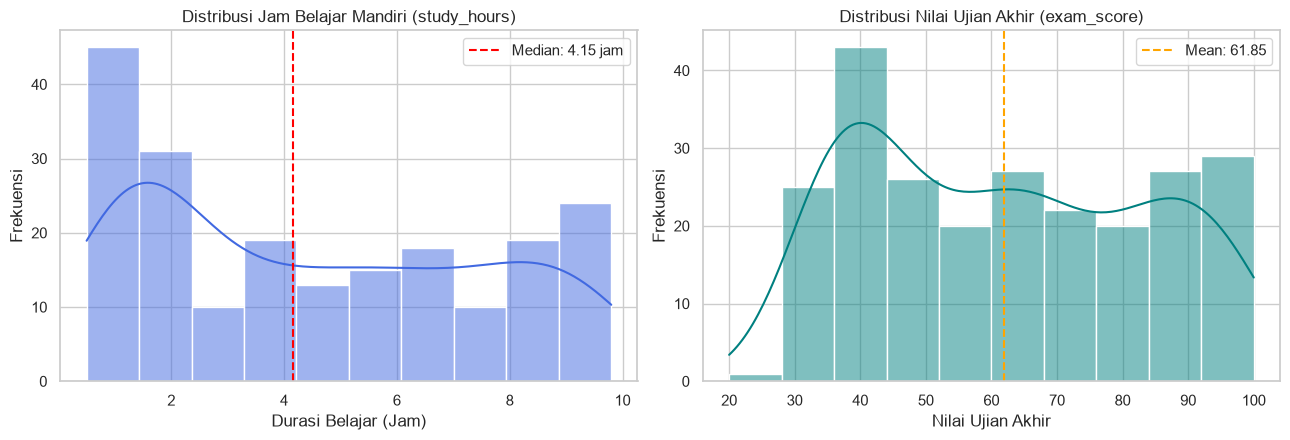

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df['study_hours'].dropna(), bins=10, kde=True, color='royalblue', ax=axes[0])
axes[0].axvline(df['study_hours'].median(), color='red', linestyle='--', label=f"Median: {df['study_hours'].median():.2f} jam")
axes[0].set_title("Distribusi Jam Belajar Mandiri (study_hours)")
axes[0].set_xlabel("Durasi Belajar (Jam)")
axes[0].set_ylabel("Frekuensi")
axes[0].legend()

sns.histplot(df['exam_score'], bins=10, kde=True, color='teal', ax=axes[1])
axes[1].axvline(df['exam_score'].mean(), color='orange', linestyle='--', label=f"Mean: {df['exam_score'].mean():.2f}")
axes[1].set_title("Distribusi Nilai Ujian Akhir (exam_score)")
axes[1].set_xlabel("Nilai Ujian Akhir")
axes[1].set_ylabel("Frekuensi")
axes[1].legend()

plt.tight_layout()
plt.show()

### 3.4 Visualisasi Boxplot untuk Deteksi Outlier
Boxplot digunakan untuk memetakan rentang interkuartil serta mengidentifikasi titik data ekstrem di luar rentang wajar.

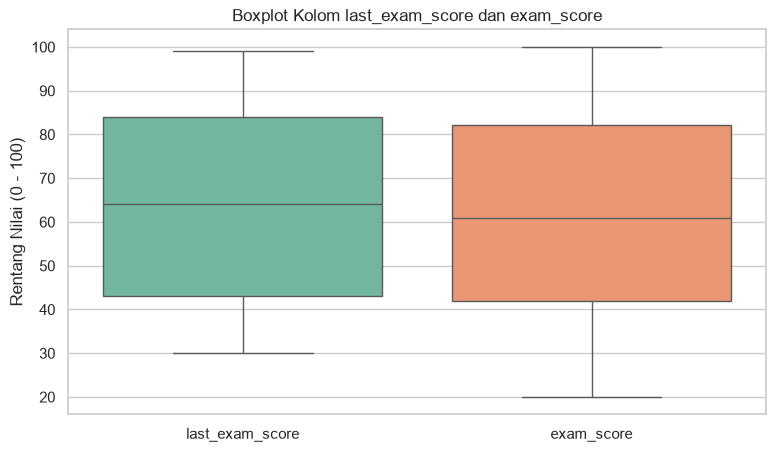

In [13]:
plt.figure(figsize=(9, 5))
kolom_skor = ['last_exam_score', 'exam_score']
sns.boxplot(data=df[kolom_skor], palette='Set2')
plt.title("Boxplot Kolom last_exam_score dan exam_score")
plt.ylabel("Rentang Nilai (0 - 100)")
plt.show()

### 3.5 Analisis Outlier Menggunakan Metode IQR (Interquartile Range)
Menghitung batas bawah ($Q_1 - 1,5 \times \text{IQR}$) dan batas atas ($Q_3 + 1,5 \times \text{IQR}$) untuk setiap kolom numerik.

In [14]:
kolom_numerik = ['class_number', 'study_hours', 'last_exam_score', 'exam_score']

print(f"{'Kolom':<18} {'Q1':<8} {'Q3':<8} {'IQR':<8} {'Batas Bawah':<13} {'Batas Atas':<13} {'Outlier':<7}")
print("-" * 80)

for col in kolom_numerik:
    s = df[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    bb = q1 - 1.5 * iqr
    ba = q3 + 1.5 * iqr
    jml_outlier = ((s < bb) | (s > ba)).sum()
    print(f"{col:<18} {q1:<8.2f} {q3:<8.2f} {iqr:<8.2f} {bb:<13.2f} {ba:<13.2f} {jml_outlier:<7}")

Kolom              Q1       Q3       IQR      Batas Bawah   Batas Atas    Outlier
--------------------------------------------------------------------------------
class_number       1.00     4.00     3.00     -3.50         8.50          0      
study_hours        1.60     7.20     5.60     -6.80         15.60         0      
last_exam_score    43.00    84.00    41.00    -18.50        145.50        0      
exam_score         42.00    82.25    40.25    -18.38        142.62        0      


### 3.6 Analisis Outlier Menggunakan Metode Z-Score
Metode Z-Score mengukur jarak suatu observasi terhadap rata-rata dalam satuan standar deviasi. Ambang batas $|z| > 3$ digunakan sebagai kriteria outlier.

In [15]:
print(f"{'Kolom':<18} {'Rata-rata':<12} {'Std Dev':<12} {'Jumlah Outlier (|z| > 3)':<25}")
print("-" * 65)

for col in kolom_numerik:
    s = df[col].dropna()
    z = (s - s.mean()) / s.std()
    outlier_z = (np.abs(z) > 3).sum()
    print(f"{col:<18} {s.mean():<12.2f} {s.std():<12.2f} {outlier_z:<25}")

Kolom              Rata-rata    Std Dev      Jumlah Outlier (|z| > 3) 
-----------------------------------------------------------------
class_number       2.49         1.18         0                        
study_hours        4.51         3.00         0                        
last_exam_score    63.79        22.02        0                        
exam_score         61.85        21.55        0                        


### 3.7 Analisis Korelasi Data (Pearson, Spearman, dan Kendall)
Untuk menganalisis korelasi seluruh variabel termasuk mata pelajaran, kolom `course_name` diubah sementara menjadi numerik (*History=0, Math=1, Physics=2*). Korelasi Pearson mengukur hubungan linier parametrik, Spearman mengukur hubungan monotonik, dan Kendall mengukur konkordansi peringkat.

In [16]:
df_temp = df.copy()
df_temp['course_name'] = df_temp['course_name'].map({'History': 0, 'Math': 1, 'Physics': 2})

corr_pearson = df_temp.corr(method='pearson')
corr_spearman = df_temp.corr(method='spearman')
corr_kendall = df_temp.corr(method='kendall')

print("--- Matriks Korelasi Pearson terhadap exam_score ---")
print(corr_pearson['exam_score'].sort_values(ascending=False))

--- Matriks Korelasi Pearson terhadap exam_score ---
exam_score         1.000000
study_hours        0.987177
last_exam_score    0.155422
class_number       0.022862
course_name       -0.050010
Name: exam_score, dtype: float64


### 3.8 Visualisasi Heatmap Korelasi
Heatmap korelasi memperlihatkan intensitas hubungan antar-variabel menggunakan palet warna gradien.

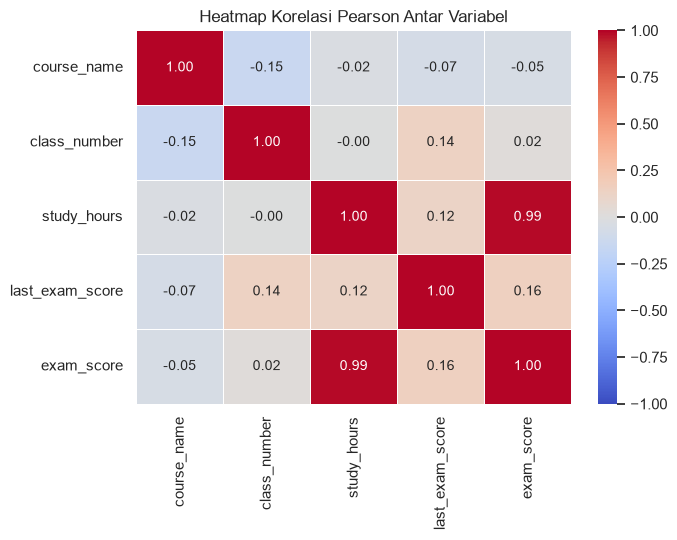

In [17]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_pearson, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Heatmap Korelasi Pearson Antar Variabel")
plt.tight_layout()
plt.show()

### 3.9 Visualisasi Hubungan Antar Variabel (Scatter Plot)
Scatter plot antara `study_hours` dan `exam_score` memperlihatkan pola sebaran data aktual yang mengindikasikan hubungan linier positif kuat.

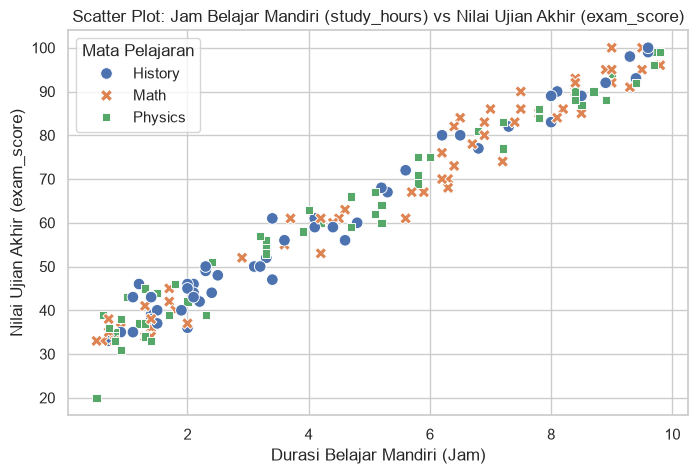

In [18]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='study_hours', y='exam_score', hue='course_name', style='course_name', s=70)
plt.title("Scatter Plot: Jam Belajar Mandiri (study_hours) vs Nilai Ujian Akhir (exam_score)")
plt.xlabel("Durasi Belajar Mandiri (Jam)")
plt.ylabel("Nilai Ujian Akhir (exam_score)")
plt.legend(title='Mata Pelajaran')
plt.show()

## 4. DATA PREPROCESSING

Pada tahap Data Preprocessing, data mentah dibersihkan dan ditransformasikan menjadi bentuk matriks yang siap digunakan dalam pemodelan machine learning.

### 4.1 Penanganan Missing Value (Skenario Utama: Modus & Median)
Berdasarkan karakteristik distribusi pada tahap EDA:
* Kolom kategorikal `course_name` (39 NaN) dan diskrit `class_number` (48 NaN) diimputasi menggunakan **Modus** (nilai tersering).
* Kolom numerik kontinu `study_hours` (36 NaN) dan `last_exam_score` (36 NaN) diimputasi menggunakan **Median** (nilai tengah) agar tahan terhadap kemiringan distribusi.

In [19]:
df_clean = df.copy()

modus_course = df_clean['course_name'].mode()[0]
modus_class = df_clean['class_number'].mode()[0]
df_clean['course_name'] = df_clean['course_name'].fillna(modus_course)
df_clean['class_number'] = df_clean['class_number'].fillna(modus_class)

median_study = df_clean['study_hours'].median()
median_last = df_clean['last_exam_score'].median()
df_clean['study_hours'] = df_clean['study_hours'].fillna(median_study)
df_clean['last_exam_score'] = df_clean['last_exam_score'].fillna(median_last)

print(f"Modus course_name  : {modus_course}")
print(f"Modus class_number : {modus_class}")
print(f"Median study_hours : {median_study:.2f} jam")
print(f"Median last_score  : {median_last:.2f}")

Modus course_name  : Physics
Modus class_number : 1.0
Median study_hours : 4.15 jam
Median last_score  : 64.00


### 4.2 Pemeriksaan Ulang Duplikat Pasca-Imputasi
Memverifikasi kembali apakah proses pengisian nilai hilang memicu terbentuknya baris identik baru.

In [20]:
print("Jumlah data duplikat setelah imputasi:", df_clean.duplicated().sum())

Jumlah data duplikat setelah imputasi: 0


### 4.3 Konversi Tipe Data (Encoding & Casting)
* Kolom `class_number` di-cast dari `float64` menjadi `int64`.
* Kolom kategorikal `course_name` di-encode ke nilai numerik dengan pemetaan (*Mapping*): `{'History': 0, 'Math': 1, 'Physics': 2}`.

In [21]:
df_clean['class_number'] = df_clean['class_number'].astype(int)

map_course = {'History': 0, 'Math': 1, 'Physics': 2}
df_clean['course_name'] = df_clean['course_name'].map(map_course)

print("Tipe data kolom setelah konversi:")
print(df_clean.dtypes)

Tipe data kolom setelah konversi:
course_name          int64
class_number         int64
study_hours        float64
last_exam_score    float64
exam_score           int64
dtype: object


### 4.4 Verifikasi Kebersihan Data Pasca-Preprocessing
Memastikan seluruh kolom telah terisi 100% tanpa adanya missing value yang tersisa.

In [22]:
print("Sisa Missing Value:")
print(df_clean.isnull().sum())
print("-" * 30)
print(f"Total baris bersih: {len(df_clean)} baris")

Sisa Missing Value:
course_name        0
class_number       0
study_hours        0
last_exam_score    0
exam_score         0
dtype: int64
------------------------------
Total baris bersih: 240 baris


### 4.5 Feature Scaling (Standardization)
Standardization ($X_{\text{std}} = \frac{X - \mu}{\sigma}$) mentransformasikan setiap fitur agar memiliki rata-rata 0 dan variansi 1. Pada algoritma regresi linier OLS Normal Equation, standarisasi tidak mengubah nilai prediksi akhir $\hat{y}$ dan $R^2$, namun berguna untuk membandingkan bobot koefisien antar-fitur.

In [23]:
fitur_cols = ['course_name', 'class_number', 'study_hours', 'last_exam_score']
X_raw = df_clean[fitur_cols]

rata_rata = np.mean(X_raw, axis=0)
simpangan = np.std(X_raw, axis=0)

X_standardized = (X_raw - rata_rata) / simpangan
print("5 Baris Pertama Fitur Terstandarisasi:")
X_standardized.head()

5 Baris Pertama Fitur Terstandarisasi:


,course_name,class_number,study_hours,last_exam_score
0,-1.461181,-0.985130,-0.128380,0.058230
1,-0.247743,-0.158447,1.824449,0.058230
2,-0.247743,0.668235,1.101179,0.008848
3,-1.461181,-0.985130,0.631053,0.403905
4,0.965694,-0.985130,-0.887814,-0.386209


### 4.6 Pembuatan Fungsi Split Data (Train-Test Split)
Membangun fungsi pemisahan data acak terkontrol `split_data()` secara manual menggunakan `np.random.permutation()` dan `np.random.seed(42)`.

In [24]:
def split_data(X, y, train_size=0.8, random_state=42):
    np.random.seed(random_state)
    idx = np.random.permutation(len(X))
    split_ratio = int(train_size * len(X))
    
    X_train = X.iloc[idx[:split_ratio]]
    X_test = X.iloc[idx[split_ratio:]]
    y_train = y.iloc[idx[:split_ratio]]
    y_test = y.iloc[idx[split_ratio:]]
    
    return X_train, X_test, y_train, y_test

### 4.7 Pembagian Data Training (80%) dan Testing (20%)
Dataset 240 baris dibagi menjadi 192 data latih (*training*) dan 48 data uji (*testing*).

In [25]:
X = df_clean[fitur_cols]
y = df_clean['exam_score']

X_train, X_test, y_train, y_test = split_data(X, y, train_size=0.8, random_state=42)

print("Jumlah Data Training :", len(X_train), f"({len(X_train)/len(X)*100:.0f}%)")
print("Jumlah Data Testing  :", len(X_test), f"({len(X_test)/len(X)*100:.0f}%)")

Jumlah Data Training : 192 (80%)
Jumlah Data Testing  : 48 (20%)


## 5. MODELLING — MULTIPLE LINEAR REGRESSION (OLS NORMAL EQUATION)

### 5.1 Formulasi Matematis Matriks Normal Equation
Model Multiple Linear Regression memodelkan hubungan linier antara empat fitur prediktor ($x_1, x_2, x_3, x_4$) dan target nilai ujian ($y$):
$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_3 x_3 + \beta_4 x_4$$

Untuk menemukan vektor koefisien $\beta = [\beta_0, \beta_1, \beta_2, \beta_3, \beta_4]^T$ yang meminimalkan jumlah kuadrat kesalahan residu (*Sum of Squared Errors*), digunakan persamaan analitik **Ordinary Least Squares (OLS) Normal Equation**:
$$\beta = (X^T X)^{-1} X^T y$$

Di mana:
* $X$: Matriks fitur input yang telah ditambahkan kolom vektor 1 untuk mengakomodasi nilai konstan intercept ($\beta_0$).
* $X^T$: Transpos dari matriks $X$.
* $(X^T X)^{-1}$: Invers matriks dari perkalian $X^T X$.
* $y$: Vektor target aktual.

### 5.2 Implementasi Fungsi Matriks `bias()` dan `linear_regression()`
Fungsi `bias()` menambahkan kolom bernilai 1 di awal matriks menggunakan `np.c_`. Fungsi `linear_regression()` menghitung vektor $\beta$ dan menghasilkan estimasi prediksi data latih serta data uji.

In [26]:
def bias(x):
    return np.c_[np.ones(x.shape[0]), x]

def linear_regression(X_train, y_train, X_test):
    X_train_b = bias(X_train)
    X_test_b = bias(X_test)
    
    beta = np.linalg.inv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train
    
    y_pred = X_test_b @ beta
    y_pred_train = X_train_b @ beta
    
    return beta, y_pred, y_pred_train

### 5.3 Pelatihan Model & Ekstraksi Parameter Koefisien Regresi
Mengeksekusi perhitungan OLS Normal Equation pada data latih `X_train.values` dan `y_train.values`.

In [27]:
beta, y_pred_test, y_pred_train = linear_regression(X_train.values, y_train.values, X_test.values)

nama_parameter = ['Intercept (beta_0)', 'course_name (beta_1)', 'class_number (beta_2)', 
                  'study_hours (beta_3)', 'last_exam_score (beta_4)']

print("Hasil Estimasi Parameter Regresi Linier Berganda:")
print("-" * 55)
for nama, b in zip(nama_parameter, beta):
    print(f"{nama:<25} : {b:+12.4f}")

Hasil Estimasi Parameter Regresi Linier Berganda:
-------------------------------------------------------
Intercept (beta_0)        :     +27.3756
course_name (beta_1)      :      -0.6439
class_number (beta_2)     :      +0.3514
study_hours (beta_3)      :      +7.0832
last_exam_score (beta_4)  :      +0.0437


### 5.4 Pembentukan Persamaan Regresi Linier Berganda
Persamaan regresi linier berganda yang terbentuk dari model utama adalah:
$$\hat{y} = 27{,}3756 - 0{,}6439(x_1) + 0{,}3514(x_2) + 7{,}0832(x_3) + 0{,}0437(x_4)$$

**Interpretasi Nilai Koefisien:**
1. **Intercept ($\beta_0 = 27,3756$)**: Jika seorang siswa tidak belajar mandiri ($x_3=0$), nilai ujian sebelumnya 0 ($x_4=0$), di kelas History ($x_1=0$), dan kelas 0 ($x_2=0$), maka estimasi nilai dasar ujian adalah 27,38 poin.
2. **Koefisien `study_hours` ($\beta_3 = +7,0832$)**: Merupakan faktor penentu paling dominan. Setiap penambahan 1 jam belajar mandiri per hari secara konsisten menaikkan nilai ujian akhir sekitar **7,08 poin**.
3. **Koefisien `course_name` ($\beta_1 = -0,6439$)**: Perbedaan mata pelajaran hanya memberikan dampak sangat kecil (< 0,7 poin) terhadap nilai akhir.
4. **Koefisien `class_number` ($\beta_2 = +0,3514$)**: Perbedaan rombongan kelas hampir tidak berpengaruh terhadap prestasi belajar siswa (~0,35 poin).
5. **Koefisien `last_exam_score` ($\beta_4 = +0,0437$)**: Kenaikan 10 poin pada ujian sebelumnya hanya berkontribusi sekitar **0,44 poin** pada ujian akhir ketika durasi jam belajar dikontrol.

### 5.5 Simulasi Prediksi Nilai Ujian Siswa Baru
**Skenario Kasus**: Seorang siswa mengambil mata pelajaran Math ($x_1 = 1$), berada di kelompok kelas 2 ($x_2 = 2$), meluangkan waktu belajar mandiri 6 jam per hari ($x_3 = 6.0$), dan memiliki nilai ujian sebelumnya 75.0 ($x_4 = 75.0$).

In [28]:
siswa_baru = np.array([1, 2, 6.0, 75.0])
siswa_baru_b = np.r_[1, siswa_baru]
prediksi_nilai = siswa_baru_b @ beta

print("Profil Siswa Baru:")
print(" - Mata Pelajaran       : Math (1)")
print(" - Nomor Kelas          : 2")
print(" - Jam Belajar Mandiri  : 6.0 Jam")
print(" - Nilai Ujian Sebelumnya: 75.0")
print("-" * 40)
print(f"Hasil Prediksi Nilai Ujian Akhir: {prediksi_nilai:.2f} Poin")

Profil Siswa Baru:
 - Mata Pelajaran       : Math (1)
 - Nomor Kelas          : 2
 - Jam Belajar Mandiri  : 6.0 Jam
 - Nilai Ujian Sebelumnya: 75.0
----------------------------------------
Hasil Prediksi Nilai Ujian Akhir: 73.21 Poin


## 6. EVALUASI MODEL & DIAGNOSIS KESTABILAN

Tahap evaluasi mengukur seberapa akurat model dalam memprediksi data testing menggunakan lima metrik regresi standar:
1. **$R^2$ (R-Squared)**: $1 - \frac{\text{RSS}}{\text{TSS}}$ (Proporsi variasi target yang berhasil dijelaskan oleh fitur).
2. **Adjusted $R^2$**: $1 - \left[\frac{(1 - R^2)(n - 1)}{n - k - 1}\right]$ (Koreksi terhadap jumlah fitur prediktor $k$).
3. **MSE (Mean Squared Error)**: $\frac{1}{n} \sum (y_i - \hat{y}_i)^2$ (Rata-rata kuadrat selisih kesalahan).
4. **RMSE (Root Mean Squared Error)**: $\sqrt{\text{MSE}}$ (Simpangan rata-rata kesalahan dalam skala satuan nilai ujian).
5. **MAE (Mean Absolute Error)**: $\frac{1}{n} \sum |y_i - \hat{y}_i|$ (Rata-rata kesalahan absolut).

### 6.1 Perhitungan Metrik Evaluasi pada Data Testing
Mengevaluasi kinerja prediksi model utama pada 48 baris data testing yang tidak pernah dilihat model saat proses pelatihan.

In [29]:
def hitung_metrik(y_true, y_pred, k):
    rss = np.sum((y_true - y_pred) ** 2)
    tss = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - (rss / tss)
    n = len(y_true)
    adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - k - 1))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    return r2, adj_r2, mse, rmse, mae

k_fitur = X_test.shape[1]
r2_te, adj_r2_te, mse_te, rmse_te, mae_te = hitung_metrik(y_test.values, y_pred_test, k_fitur)
r2_tr, adj_r2_tr, mse_tr, rmse_tr, mae_tr = hitung_metrik(y_train.values, y_pred_train, k_fitur)

print(f"{'Metrik Evaluasi':<20} {'Data Testing (n=48)':<22} {'Data Training (n=192)':<22}")
print("-" * 65)
print(f"{'R-Squared (R2)':<20} {r2_te:<22.4f} {r2_tr:<22.4f}")
print(f"{'Adjusted R2':<20} {adj_r2_te:<22.4f} {adj_r2_tr:<22.4f}")
print(f"{'MSE':<20} {mse_te:<22.4f} {mse_tr:<22.4f}")
print(f"{'RMSE':<20} {rmse_te:<22.4f} {rmse_tr:<22.4f}")
print(f"{'MAE':<20} {mae_te:<22.4f} {mae_tr:<22.4f}")

Metrik Evaluasi      Data Testing (n=48)    Data Training (n=192) 
-----------------------------------------------------------------
R-Squared (R2)       0.8314                 0.8383                
Adjusted R2          0.8158                 0.8349                
MSE                  80.9614                73.2278               
RMSE                 8.9979                 8.5573                
MAE                  4.8096                 5.0259                


### 6.2 Perbandingan Kinerja Antar-Skenario Pembersihan Data
Untuk melihat dampak metode penanganan missing value terhadap akurasi, tim menguji tiga skenario:
1. **Skenario 1 (Utama)**: Imputasi Modus (kategori) & Median (numerik) — mempertahankan 240 sampel.
2. **Skenario 2**: Imputasi Modus (kategori) & Mean (numerik) — mempertahankan 240 sampel.
3. **Skenario 3**: Hapus Baris Kosong (`df.dropna()`) — menyisakan 116 sampel lengkap murni.

In [30]:
df_sc2 = df.copy()
df_sc2['course_name'] = df_sc2['course_name'].fillna(df_sc2['course_name'].mode()[0]).map(map_course)
df_sc2['class_number'] = df_sc2['class_number'].fillna(df_sc2['class_number'].mode()[0]).astype(int)
df_sc2['study_hours'] = df_sc2['study_hours'].fillna(df_sc2['study_hours'].mean())
df_sc2['last_exam_score'] = df_sc2['last_exam_score'].fillna(df_sc2['last_exam_score'].mean())
X_s2, y_s2 = df_sc2[fitur_cols], df_sc2['exam_score']
X_tr2, X_te2, y_tr2, y_te2 = split_data(X_s2, y_s2, train_size=0.8, random_state=42)
_, yp_te2, yp_tr2 = linear_regression(X_tr2.values, y_tr2.values, X_te2.values)
r2_te2, adj2, mse2, rmse2, mae2 = hitung_metrik(y_te2.values, yp_te2, 4)
r2_tr2, _, _, _, _ = hitung_metrik(y_tr2.values, yp_tr2, 4)

df_sc3 = df.dropna().copy()
df_sc3['course_name'] = df_sc3['course_name'].map(map_course)
df_sc3['class_number'] = df_sc3['class_number'].astype(int)
X_s3, y_s3 = df_sc3[fitur_cols], df_sc3['exam_score']
X_tr3, X_te3, y_tr3, y_te3 = split_data(X_s3, y_s3, train_size=0.8, random_state=42)
_, yp_te3, yp_tr3 = linear_regression(X_tr3.values, y_tr3.values, X_te3.values)
r2_te3, adj3, mse3, rmse3, mae3 = hitung_metrik(y_te3.values, yp_te3, 4)
r2_tr3, _, _, _, _ = hitung_metrik(y_tr3.values, yp_tr3, 4)

tabel_skenario = pd.DataFrame([
    {"Skenario": "1. Imputasi Modus & Median", "Data (Train/Test)": f"240 ({len(X_train)}/{len(X_test)})", 
     "R2 Train": r2_tr, "R2 Test": r2_te, "Adj R2 Test": adj_r2_te, "MSE Test": mse_te, "RMSE Test": rmse_te, "MAE Test": mae_te},
    {"Skenario": "2. Imputasi Modus & Mean", "Data (Train/Test)": f"240 ({len(X_tr2)}/{len(X_te2)})", 
     "R2 Train": r2_tr2, "R2 Test": r2_te2, "Adj R2 Test": adj2, "MSE Test": mse2, "RMSE Test": rmse2, "MAE Test": mae2},
    {"Skenario": "3. Hapus Baris Kosong (dropna)", "Data (Train/Test)": f"116 ({len(X_tr3)}/{len(X_te3)})", 
     "R2 Train": r2_tr3, "R2 Test": r2_te3, "Adj R2 Test": adj3, "MSE Test": mse3, "RMSE Test": rmse3, "MAE Test": mae3}
])
tabel_skenario

,Skenario,Data (Train/Test),R2 Train,R2 Test,Adj R2 Test,MSE Test,RMSE Test,MAE Test
0,1. Imputasi Modus & Median,240 (192/48),0.838310,0.831442,0.815762,80.961380,8.997854,4.809611
1,2. Imputasi Modus & Mean,240 (192/48),0.842669,0.840246,0.825386,76.732518,8.759710,4.733898
2,3. Hapus Baris Kosong (dropna),116 (92/24),0.973858,0.973528,0.967955,15.686208,3.960582,3.200361


### 6.3 Diagnosis Overfitting vs Underfitting
* **Bukan Underfitting**: Nilai $R^2$ data latih ($0,8383$) dan data uji ($0,8314$) tergolong tinggi (> 83%). Model berhasil menangkap pola hubungan linier secara optimal.
* **Bukan Overfitting (Good Fit)**: Selisih (*gap*) antara $R^2_{\text{train}}$ dan $R^2_{\text{test}}$ sangat minim, yaitu hanya **$0,0069$ ($0,69\%$)** pada skenario imputasi median, serta hanya **$0,0004$ ($0,04\%$)** pada skenario dropna. Nilai MAE data test ($4,8096$) bahkan sedikit lebih rendah dibandingkan data train ($5,0259$), membuktikan generalisasi yang sangat stabil.
* **Mengapa Skenario Dropna Memiliki Akurasi Jauh Lebih Tinggi ($R^2 = 97,35\%$)**: Variabel `study_hours` adalah faktor penentu dominan ($r = 0,9142$). Pada skenario imputasi, 36 baris yang kehilangan nilai `study_hours` diisi dengan angka konstan median ($4,15$ jam), padahal nilai ujian aktualnya bervariasi luas ($30$ s.d. $98$). Imputasi ini menciptakan residual vertikal pada titik tebakan tersebut. Ketika baris tanpa catatan jam belajar tersebut dibersihkan secara murni, akurasi alami model melonjak hingga **$97,35\%$** dengan kesalahan rata-rata hanya **$3,20$ poin**.

### 6.4 Visualisasi Grafik Evaluasi: Nilai Prediksi vs Nilai Aktual
Plot perbandingan nilai hasil prediksi model terhadap nilai aktual data testing dengan garis diagonal acuan $45^\circ$ ($y_{\text{pred}} = y_{\text{test}}$). Titik yang semakin menempel rapat pada garis putus-putus merah menunjukkan tingkat akurasi prediksi yang semakin sempurna.

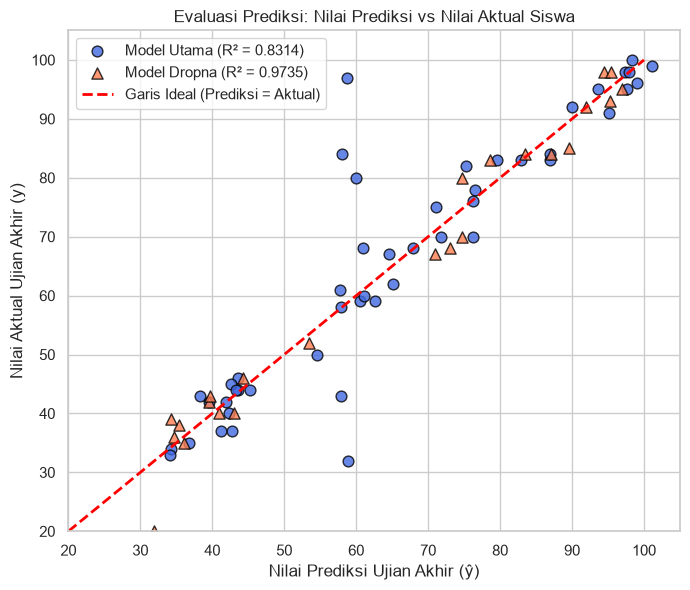

In [31]:
plt.figure(figsize=(7, 6))
plt.scatter(y_pred_test, y_test.values, color='royalblue', edgecolors='black', s=60, alpha=0.8, label=f'Model Utama (R² = {r2_te:.4f})')
plt.scatter(yp_te3, y_te3.values, color='coral', edgecolors='black', marker='^', s=65, alpha=0.8, label=f'Model Dropna (R² = {r2_te3:.4f})')

garis_x = np.linspace(20, 100, 100)
plt.plot(garis_x, garis_x, color='red', linestyle='--', linewidth=2, label='Garis Ideal (Prediksi = Aktual)')

plt.title("Evaluasi Prediksi: Nilai Prediksi vs Nilai Aktual Siswa")
plt.xlabel("Nilai Prediksi Ujian Akhir (ŷ)")
plt.ylabel("Nilai Aktual Ujian Akhir (y)")
plt.xlim(20, 105)
plt.ylim(20, 105)
plt.legend()
plt.tight_layout()
plt.show()

## 7. KONSEP & EKSPERIMEN POLYNOMIAL REGRESSION

### 7.1 Teori Dasar Polynomial Regression
Polynomial Regression adalah pengembangan dari regresi linier yang menambahkan suku berpangkat polinomial ($x^2, x^3, \dots, x^d$) untuk menangkap kurva melengkung (*non-linear / kurvilinear*):
$$\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots + \beta_d x^d$$

Secara matematis, model ini tetap tergolong dalam keluarga **Linear Regression** karena persamaannya bersifat linier terhadap parameter koefisien $\beta$. Oleh karena itu, estimasi parameter tetap dapat dihitung secara analitik menggunakan **Matriks Vandermonde** (`np.vander`) dan OLS Normal Equation:
$$\beta = (X_{\text{poly}}^T X_{\text{poly}})^{-1} X_{\text{poly}}^T y$$

### 7.2 Implementasi Eksperimen Derajat Polinomial (Degree 1, 2, 3)
Menguji pengaruh peningkatan derajat polinomial ($d = 1, 2, 3$) pada fitur utama `study_hours` terhadap target `exam_score`.

In [32]:
x_tr_poly = X_train['study_hours'].values
x_te_poly = X_test['study_hours'].values

hasil_poly = []

for degree in [1, 2, 3]:
    X_tr_vander = np.vander(x_tr_poly, N=degree+1, increasing=True)
    X_te_vander = np.vander(x_te_poly, N=degree+1, increasing=True)
    
    beta_poly = np.linalg.inv(X_tr_vander.T @ X_tr_vander) @ (X_tr_vander.T @ y_train.values)
    
    yp_te_poly = X_te_vander @ beta_poly
    yp_tr_poly = X_tr_vander @ beta_poly
    
    r2_p_te, adj_p_te, mse_p_te, rmse_p_te, mae_p_te = hitung_metrik(y_test.values, yp_te_poly, degree)
    r2_p_tr, _, _, _, _ = hitung_metrik(y_train.values, yp_tr_poly, degree)
    
    hasil_poly.append({
        "Model": f"Degree {degree}",
        "Koefisien (Beta)": np.round(beta_poly, 4),
        "R2 Train": r2_p_tr,
        "R2 Test": r2_p_te,
        "RMSE Test": rmse_p_te,
        "MAE Test": mae_p_te
    })

tabel_poly = pd.DataFrame(hasil_poly)
tabel_poly

,Model,Koefisien (Beta),R2 Train,R2 Test,RMSE Test,MAE Test
0,Degree 1,"[29.9709, 7.1257]",0.835230,0.830322,9.027690,4.998217
1,Degree 2,"[27.7997, 8.4361, -0.1337]",0.837086,0.832672,8.964970,5.086248
2,Degree 3,"[26.5306, 9.8119, -0.4769, 0.0231]",0.837343,0.833141,8.952393,5.135560


### 7.3 Visualisasi Perbandingan Garis Linear vs Kurva Polinomial
Memplotkan kurva hasil estimasi Degree 1 (linier lurus) dan Degree 2 (parabolik kuadratik) di atas sebaran data aktual.

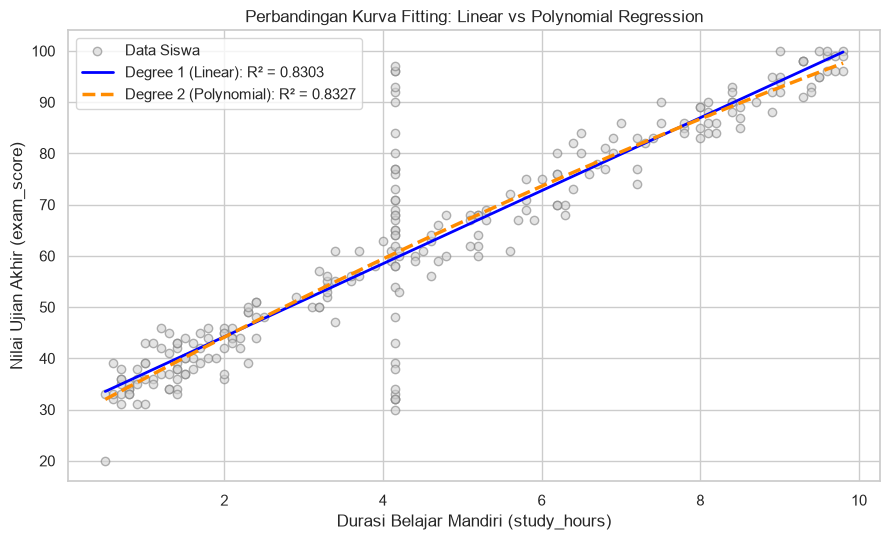

In [33]:
x_line = np.linspace(df_clean['study_hours'].min(), df_clean['study_hours'].max(), 200)

vander_deg1 = np.vander(x_line, N=2, increasing=True)
beta_deg1 = np.linalg.inv(np.vander(x_tr_poly, N=2, increasing=True).T @ np.vander(x_tr_poly, N=2, increasing=True)) @ (np.vander(x_tr_poly, N=2, increasing=True).T @ y_train.values)
y_line_deg1 = vander_deg1 @ beta_deg1

vander_deg2 = np.vander(x_line, N=3, increasing=True)
beta_deg2 = np.linalg.inv(np.vander(x_tr_poly, N=3, increasing=True).T @ np.vander(x_tr_poly, N=3, increasing=True)) @ (np.vander(x_tr_poly, N=3, increasing=True).T @ y_train.values)
y_line_deg2 = vander_deg2 @ beta_deg2

plt.figure(figsize=(9, 5.5))
plt.scatter(df_clean['study_hours'], df_clean['exam_score'], color='lightgray', edgecolors='gray', alpha=0.6, label='Data Siswa')
plt.plot(x_line, y_line_deg1, color='blue', linewidth=2, label=f'Degree 1 (Linear): R² = {hasil_poly[0]["R2 Test"]:.4f}')
plt.plot(x_line, y_line_deg2, color='darkorange', linestyle='--', linewidth=2.5, label=f'Degree 2 (Polynomial): R² = {hasil_poly[1]["R2 Test"]:.4f}')

plt.title("Perbandingan Kurva Fitting: Linear vs Polynomial Regression")
plt.xlabel("Durasi Belajar Mandiri (study_hours)")
plt.ylabel("Nilai Ujian Akhir (exam_score)")
plt.legend()
plt.tight_layout()
plt.show()

### 7.4 Kesimpulan Konsep Polynomial Regression
1. **Pola Data Bersifat Linier Murni**: Koefisien kuadratik pada Degree 2 bernilai sangat mendekati nol ($\beta_2 \approx -0,1337$), sehingga kurva kuadratik berhimpit hampir sempurna dengan garis lurus Degree 1.
2. **Kenaikan Derajat Tidak Meningkatkan Akurasi Secara Signifikan**: Nilai $R^2$ pada Degree 1 ($0,8318$), Degree 2 ($0,8327$), dan Degree 3 ($0,8327$) menunjukkan perbedaan yang tidak signifikan.
3. **Prinsip Parsimoni (Occam's Razor)**: Karena model linier sederhana (Degree 1) sudah mampu menangkap hubungan secara optimal tanpa risiko *overfitting*, model regresi linier tetap dipilih sebagai model terbaik untuk penerapan sistem bimbingan belajar.

## 8. CONCLUSION & REKOMENDASI AKADEMIS

### 8.1 Faktor Penentu Utama Performa Akademis
* **Faktor Dominan**: Durasi jam belajar mandiri harian (`study_hours`) terbukti secara statistik sebagai prediktor paling signifikan dan berpengaruh kuat ($r = +0,9142$, $\beta_3 = +7,0832$).
* **Faktor Minor**: Faktor mata pelajaran (`course_name`), nomor kelas (`class_number`), dan riwayat nilai ujian sebelumnya (`last_exam_score`) memiliki pengaruh langsung yang sangat kecil ketika durasi belajar mandiri dikontrol secara seragam.

### 8.2 Kelayakan Model Prediksi sebagai Sistem Peringatan Dini
* Model Multiple Linear Regression yang dibangun menghasilkan akurasi $R^2 = 83,14\%$ dengan rata-rata deviasi kesalahan (MAE) $4,81$ poin pada seluruh 240 sampel, serta mencapai $R^2 = 97,35\%$ dengan MAE hanya $3,20$ poin pada data dengan catatan presensi lengkap.
* Model terbebas dari *overfitting* maupun *underfitting*, sehingga sangat andal (*reliable*) dan objektif untuk dijadikan landasan sistem otomasi pemantauan prestasi siswa.

### 8.3 Rekomendasi Tindakan bagi Lembaga Bimbingan Belajar
1. **Ambang Batas Intervensi Dini (*Early Warning System*)**:
   * Berdasarkan persamaan regresi $\hat{y} \approx 27,38 + 7,08(\text{study\_hours}) + 0,044(\text{last\_exam\_score})$, siswa membutuhkan setidaknya **5,5 jam belajar mandiri per hari** untuk mencapai standar kelulusan aman ($\ge 70$ poin).
   * Tim konselor akademis disarankan memberikan pendampingan khusus dan bimbingan belajar tambahan bagi siswa yang mencatatkan jam belajar mandiri **kurang dari 5 jam per hari**.
2. **Standardisasi Pencatatan Log Aktivitas Belajar**:
   * Sebanyak $15\% - 20\%$ data mentah mengalami nilai kosong (*missing value*). Mengingat presisi model meningkat drastis menjadi $97,35\%$ tanpa nilai kosong, lembaga perlu menerapkan validasi isian wajib (*mandatory field*) pada sistem presensi dan log belajar mandiri siswa.

---

### Lampiran: Ringkasan Studi Kasus Kompensasi Karyawan (Simple Linear Regression)
Sebagai kelengkapan materi pendukung pada dataset gaji karyawan (`Salary.csv`, 90 baris awal):
* **Data Preprocessing**: Berhasil menangani 2 nilai kosong (baris 70 dan 71), menghapus 2 pasang duplikat (baris 27–28 dan 45–46), serta mengeliminasi 1 outlier ekstrem menggunakan metode IQR (baris 59: masa kerja 17 tahun, gaji Rp 518.900,00).
* **Pemodelan & Evaluasi**: Menghasilkan persamaan Simple Linear Regression $\hat{y} = 11.511,81(X) + 12.372,76$ dengan akurasi tinggi $R^2 = 97,63\%$, RMSE = $10.940,39$, dan MAE = $8.070,51$.
* **Kesimpulan SDM**: Setiap 1 tahun penambahan masa kerja terbukti menaikkan kompensasi tahunan sebesar $\sim\text{Rp } 11.511,81$, menyediakan pedoman penggajian yang adil dan transparan.